# 5. All together

In [1]:
import numpy as np
from textsynth import (
    Blobify,
    BorrowedGlyph,
    ComponentFilter,
    GlyphSubstitution,
    InkBleed,
    Layout,
    Smudge,
    Speckle,
    Synthesizer,
    orthographic_variation,
)
from nbutil import DONOR, FONT, sheet

TEXT = "سايا ممباچ سورت خبر"
mim = GlyphSubstitution("مم", BorrowedGlyph(DONOR, "A"))

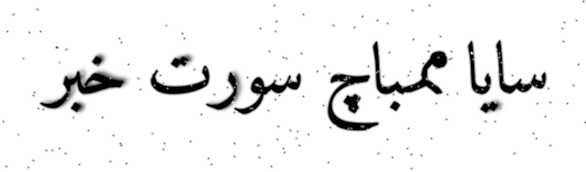

In [2]:
distressed = Synthesizer(
    font=FONT,
    layout=Layout(size=72, tracking=-1, supersample=2, jitter_y=0.6),
    font_patches=[mim],
    effects=[
        Smudge(length=7, strength=0.75, select=ComponentFilter(min_area=20, count=6)),
        Blobify(merge_radius=4, probability=0.8),
        InkBleed(1.0, strength=0.6),
        Speckle(density=0.0015, holes=0.01),
    ],
    seed=7,
)
distressed(TEXT)

## The dataset

One synthesizer makes one sample for each call. The spelling variation changes
the string, so each row is a different hand.

textsynth patches the font one time, at the first render, and uses it again
for each sample.

seed 0: سا ممباچ سۏرت خبر
seed 1: سايا ممباچ سورت خبر
seed 2: سیا ممباچ سورت خبر
seed 3: سای ممباچ سورت خبر
seed 4: ساا ممباچ سورت خبر
seed 5: ساي ممباچ سورت خبر


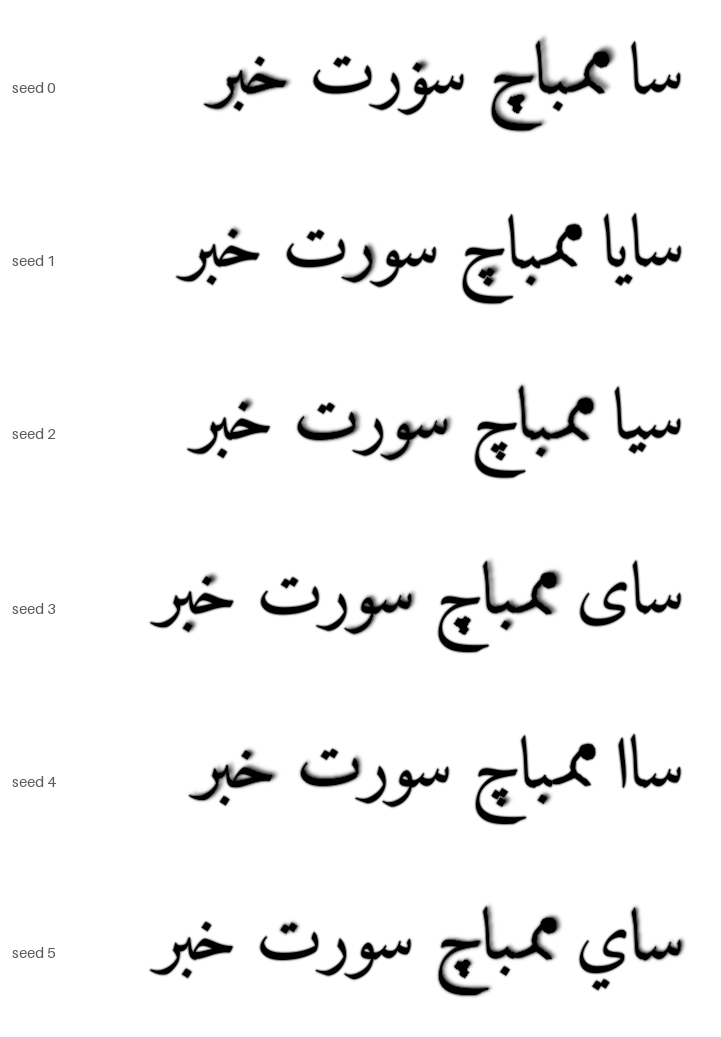

In [3]:
varied = Synthesizer(
    font=FONT,
    layout=Layout(size=72, tracking=-1, supersample=2, jitter_x=0.5, jitter_y=0.8),
    text_rules=[orthographic_variation(swap=0.35, drop_letters=0.1)],
    font_patches=[mim],
    effects=[Smudge(length=5), Blobify(), InkBleed(1.0, strength=0.5)],
)

rows = []
for i in range(6):
    spelling = varied.apply_text_rules(TEXT, np.random.default_rng(i))
    rows.append((f"seed {i}", varied.render(TEXT, seed=i)))
    print(f"seed {i}: {spelling}")
sheet(rows, gutter=110)

## The cost of each sample

In [4]:
import time

varied.patched_font  # force the patch so it is not timed as drawing

start = time.perf_counter()
for i in range(20):
    varied.render(TEXT, seed=i)
print(f"{(time.perf_counter() - start) / 20 * 1000:.1f} ms per sample")

18.2 ms per sample


## The label goes with the image

A training set needs the string that textsynth drew, and not the string you
gave it. `apply_text_rules` with the same seed gives that string back.

In [5]:
samples = [(varied.apply_text_rules(TEXT, np.random.default_rng(i)), varied.render(TEXT, seed=i)) for i in range(3)]
for label, image in samples:
    print(f"{image.width:>4} x {image.height:<4}  {label}")

 557 x 173   سا ممباچ سۏرت خبر
 585 x 172   سايا ممباچ سورت خبر
 574 x 175   سیا ممباچ سورت خبر
